# Praktikum 4 - Klasifikasi Citra Wajah (LFW)


## 1. Load dataset wajah


In [1]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print('Nama kelas target:')
print(faces.target_names)
print(f'Jumlah kelas: {len(faces.target_names)}')
print(f'Dimensi data citra: {faces.images.shape}')


Nama kelas target:
['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah kelas: 8
Dimensi data citra: (1348, 62, 47)


## 2. Contoh citra wajah


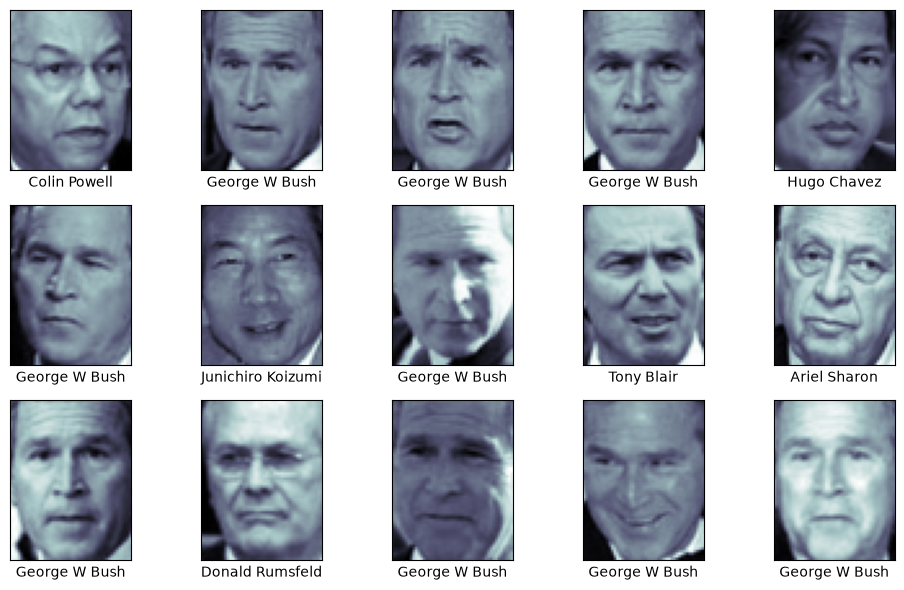

In [2]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(10, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.tight_layout()
plt.show()


## 3. Pipeline PCA (150 komponen) dan SVM RBF


In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)


## 4. Split data train dan test


In [4]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)
print(f'Jumlah data train: {Xtrain.shape[0]}')
print(f'Jumlah data test : {Xtest.shape[0]}')


Jumlah data train: 1011
Jumlah data test : 337


## 5. Tuning C dan gamma dengan GridSearchCV


In [5]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print('Parameter terbaik:')
print(grid.best_params_)
print(f'Akurasi validasi terbaik: {grid.best_score_:.4f}')


CPU times: total: 3min 42s
Wall time: 29 s
Parameter terbaik:
{'svc__C': 5, 'svc__gamma': 0.001}
Akurasi validasi terbaik: 0.8289


## Prediksi data test


In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)


## 6. Visualisasi hasil prediksi


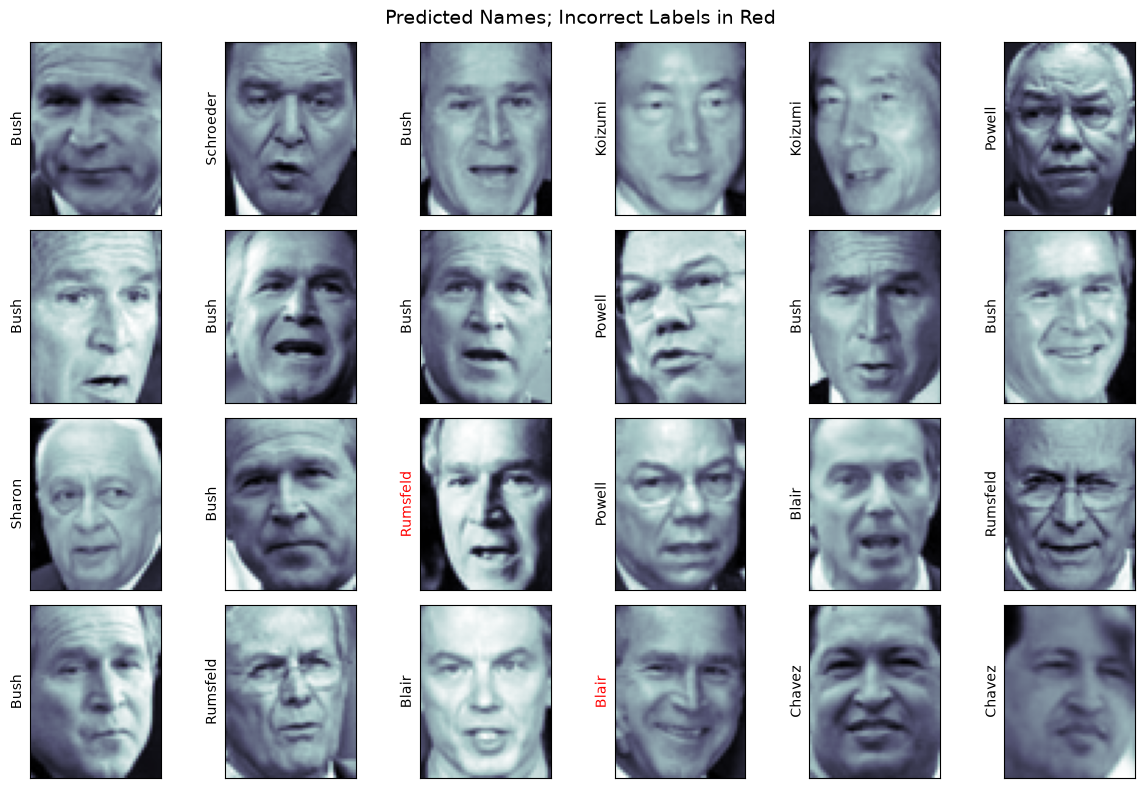

In [7]:
fig, ax = plt.subplots(4, 6, figsize=(12, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.tight_layout()
plt.show()


## 7. Evaluasi model (classification report)


In [8]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))


                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



## Confusion matrix


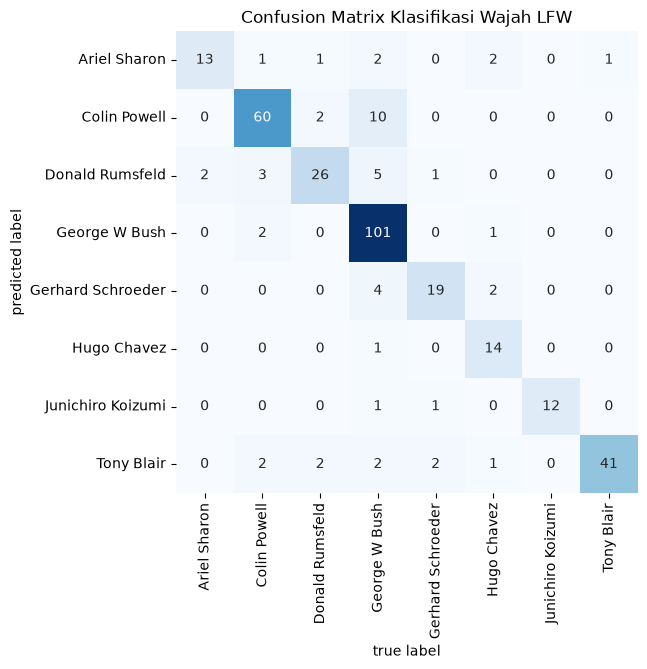

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(8, 6))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names, cmap='Blues')
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.title('Confusion Matrix Klasifikasi Wajah LFW')
plt.show()
